### BAG OF WORDS

In [1]:
import re
import seaborn as sns
import pandas as pd
import numpy as np
import nltk
import heapq
import matplotlib.pyplot as plt


In [2]:
text="""Once upon a time, a young coder named Jack traded his last dollar for five NLP Magic Beans, planting them to see how machines learn to read. The One-Hot Encoding bean grew rigid, lonely stalks where every word stood isolated, while the Bag-of-Words bean gathered them into a chaotic sack that counted frequencies but scrambled the grammar. To fix the mess, the N-Grams bean sprouted interconnected pods to preserve local word order, and the clever TF-IDF bean grew a pair of scales to weigh unique keywords while ignoring useless filler words like "the." Finally, the Word2Vec bean opened a floating mathematical portal, allowing words with similar meanings to drift close together so the computer could truly understand that a "magic bean" and a "digital seed" were cousins in the digital sky."""


In [3]:
text=text.lower()
dataset = nltk.sent_tokenize(text)

In [4]:
for i in range(len(dataset)):
    dataset[i] = re.sub(r'\W', ' ', dataset[i])
    dataset[i] = re.sub(r'\s+', ' ', dataset[i])

for i, sentence in enumerate(dataset):
    print(f"Sentence {i+1}: {sentence}")

Sentence 1: once upon a time a young coder named jack traded his last dollar for five nlp magic beans planting them to see how machines learn to read 
Sentence 2: the one hot encoding bean grew rigid lonely stalks where every word stood isolated while the bag of words bean gathered them into a chaotic sack that counted frequencies but scrambled the grammar 
Sentence 3: to fix the mess the n grams bean sprouted interconnected pods to preserve local word order and the clever tf idf bean grew a pair of scales to weigh unique keywords while ignoring useless filler words like the 
Sentence 4: finally the word2vec bean opened a floating mathematical portal allowing words with similar meanings to drift close together so the computer could truly understand that a magic bean and a digital seed were cousins in the digital sky 


In [5]:
from nltk.corpus import stopwords
wordcount = {}

for data in dataset:
    words = nltk.word_tokenize(data)
    for word in words:
        if word not in wordcount:
            wordcount[word] = 1
        else:
            wordcount[word] += 1
wordcount = {word: count for word, count in wordcount.items() if word not in set(stopwords.words('english'))}

freq= pd.DataFrame(list(wordcount.items()), columns=['Word', 'Frequency'])

freq = freq.sort_values(by='Frequency', ascending=False)

print(freq)

       Word  Frequency
21     bean          6
31    words          3
77  digital          2
27     word          2
11    magic          2
..      ...        ...
28    stood          1
26    every          1
25   stalks          1
24   lonely          1
80      sky          1

[81 rows x 2 columns]


In [6]:
freq_words = heapq.nlargest(10, wordcount, key=wordcount.get)

print(f"Top 10 frequent words: {freq_words}")

top_words = sorted(wordcount.items(), key=lambda x: x[1], reverse=True)[:10]
words, counts = zip(*top_words)


Top 10 frequent words: ['bean', 'words', 'magic', 'grew', 'word', 'digital', 'upon', 'time', 'young', 'coder']


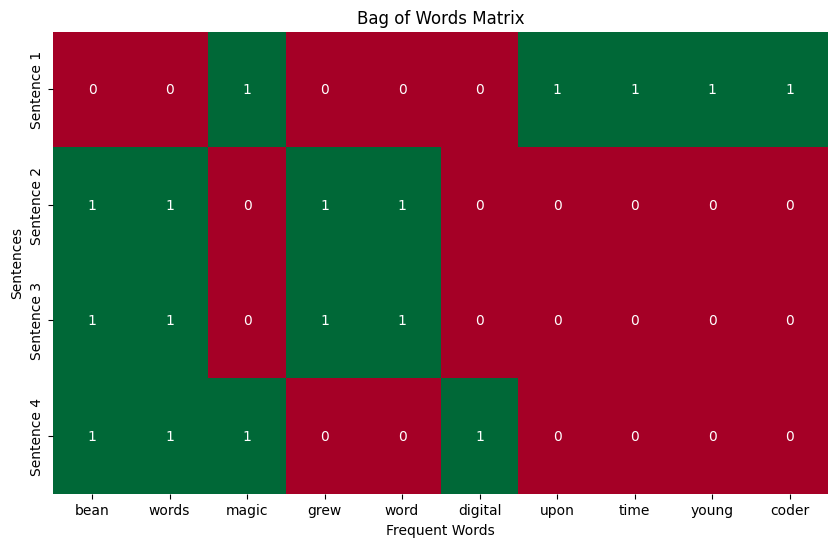

In [ ]:
X = []
for data in dataset:
    vector = []
    for word in freq_words:
        if word in nltk.word_tokenize(data):
            vector.append(1)
        else:
            vector.append(0)
    X.append(vector)

X = np.asarray(X)

plt.figure(figsize=(10, 6))
sns.heatmap(X, cmap='RdYlGn', cbar=False, annot=True, fmt="d", xticklabels=freq_words, yticklabels=[f"Sentence {i+1}" for i in range(len(dataset))])

plt.title('Bag of Words Matrix')
plt.xlabel('Frequent Words')
plt.ylabel('Sentences')
plt.show()

### 1 HOT ENCODING

In [7]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(sparse_output=False)
one_hot = encoder.fit_transform(top_words)
print("One-Hot Matrix:\n", one_hot)

One-Hot Matrix:
 [[1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0.]
 [0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]]


In [8]:
print("Vocabulary:", encoder.get_feature_names_out())

Vocabulary: ['x0_bean' 'x0_coder' 'x0_digital' 'x0_grew' 'x0_magic' 'x0_time'
 'x0_upon' 'x0_word' 'x0_words' 'x0_young' 'x1_1' 'x1_2' 'x1_3' 'x1_6']


### TF-IDF

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf=TfidfVectorizer()
matrix=tfidf.fit_transform(dataset)
print("Vocabulary:", tfidf.get_feature_names_out())
print("TF-IDF Matrix:\n", matrix.toarray())

Vocabulary: ['allowing' 'and' 'bag' 'bean' 'beans' 'but' 'chaotic' 'clever' 'close'
 'coder' 'computer' 'could' 'counted' 'cousins' 'digital' 'dollar' 'drift'
 'encoding' 'every' 'filler' 'finally' 'five' 'fix' 'floating' 'for'
 'frequencies' 'gathered' 'grammar' 'grams' 'grew' 'his' 'hot' 'how' 'idf'
 'ignoring' 'in' 'interconnected' 'into' 'isolated' 'jack' 'keywords'
 'last' 'learn' 'like' 'local' 'lonely' 'machines' 'magic' 'mathematical'
 'meanings' 'mess' 'named' 'nlp' 'of' 'once' 'one' 'opened' 'order' 'pair'
 'planting' 'pods' 'portal' 'preserve' 'read' 'rigid' 'sack' 'scales'
 'scrambled' 'see' 'seed' 'similar' 'sky' 'so' 'sprouted' 'stalks' 'stood'
 'tf' 'that' 'the' 'them' 'time' 'to' 'together' 'traded' 'truly'
 'understand' 'unique' 'upon' 'useless' 'weigh' 'were' 'where' 'while'
 'with' 'word' 'word2vec' 'words' 'young']
TF-IDF Matrix:
 [[0.         0.         0.         0.         0.20466712 0.
  0.         0.         0.         0.20466712 0.         0.
  0.         0.  

### Word2Vec

In [24]:
from gensim.models import Word2Vec
sentences = [sentence.split() for sentence in dataset]
word2vec= Word2Vec(sentences, vector_size=4, window=2, min_count=1, workers=1, seed=42)


In [25]:
# Print the entire vocabulary list at once
print(word2vec.wv.index_to_key)



['the', 'a', 'bean', 'to', 'words', 'digital', 'and', 'that', 'of', 'while', 'word', 'grew', 'them', 'magic', 'sky', 'in', 'cousins', 'were', 'seed', 'understand', 'truly', 'could', 'computer', 'so', 'together', 'close', 'drift', 'meanings', 'similar', 'with', 'allowing', 'portal', 'mathematical', 'floating', 'opened', 'word2vec', 'finally', 'like', 'filler', 'useless', 'ignoring', 'keywords', 'unique', 'weigh', 'scales', 'pair', 'idf', 'tf', 'clever', 'order', 'local', 'preserve', 'pods', 'interconnected', 'sprouted', 'grams', 'n', 'mess', 'fix', 'grammar', 'scrambled', 'but', 'frequencies', 'counted', 'sack', 'chaotic', 'into', 'gathered', 'bag', 'isolated', 'stood', 'every', 'where', 'stalks', 'lonely', 'rigid', 'encoding', 'hot', 'one', 'read', 'learn', 'machines', 'how', 'see', 'planting', 'beans', 'nlp', 'five', 'for', 'dollar', 'last', 'his', 'traded', 'jack', 'named', 'coder', 'young', 'time', 'upon', 'once']


In [26]:
analogy_result = word2vec.wv.most_similar(positive=['jack', 'computer'], negative=['coder'], topn=1)
print(f"1. Analogy Result (jack - coder + computer): {analogy_result}\n")

1. Analogy Result (jack - coder + computer): [('stalks', 0.9569048881530762)]



In [ ]:

top_similar = word2vec.wv.most_similar('bean', topn=3)
print(f"2A. Top 3 closest words to 'bean': {top_similar}")
cosine_sim = word2vec.wv.similarity('magic', 'bean')
print(f"2B. Cosine Similarity ('magic', 'bean'): {cosine_sim:.4f}")
distance = word2vec.wv.distance('magic', 'bean')
print(f"2C. Cosine Distance ('magic', 'bean'): {distance:.4f}")
phrase_sim = word2vec.wv.n_similarity(['magic', 'bean'], ['digital', 'seed'])
print(f"2D. Sentence-level Similarity: {phrase_sim:.4f}\n")

2A. Top 3 closest words to 'bean': [('learn', 0.977703332901001), ('sprouted', 0.9735631942749023), ('understand', 0.9534547328948975)]
2B. Cosine Similarity ('magic', 'bean'): -0.4919
2C. Cosine Distance ('magic', 'bean'): 1.4919
2D. Sentence-level Similarity: 0.5915



In [28]:

odd_one = word2vec.wv.doesnt_match(['bean', 'seed', 'stalk', 'computer'])
print(f"3. Odd-One-Out ('bean', 'seed', 'stalk', 'computer'): '{odd_one}'\n")

3. Odd-One-Out ('bean', 'seed', 'stalk', 'computer'): 'computer'



In [30]:

word_idx = word2vec.wv.key_to_index['jack']
print(f"4A. Vocabulary Index of 'jack': {word_idx}")
word_string = word2vec.wv.index_to_key[0]
print(f"4B. Most frequent word at Index 0: '{word_string}'")

vocab_size = len(word2vec.wv)
print(f"4C. Total unique words in vocabulary: {vocab_size}")

raw_count = word2vec.wv.get_vecattr('bean', 'count')
print(f"4D. Number of times 'bean' appeared in training data: {raw_count}")

raw_vector = word2vec.wv['jack']
print(f"4E. Raw 5-dimensional vector for 'jack':\n {raw_vector}\n")

4A. Vocabulary Index of 'jack': 93
4B. Most frequent word at Index 0: 'the'
4C. Total unique words in vocabulary: 100
4D. Number of times 'bean' appeared in training data: 6
4E. Raw 5-dimensional vector for 'jack':
 [-0.04499698 -0.06344866  0.1935246  -0.20235927]

